# Explications *feature-based* avec LIME et SHAP
## Objectifs
* Générer des explications locales avec LIME et SHAP sur un modèle de forêt aléatoire entraîné sur des données tabulaires [(Credit Card Customer)](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers/data) *(les données en format CSV sont disponibles sur Moodle)*
* Examiner empiriquement l'instabilité de LIME en comparaison avec la stabilité des valeurs de Shapley
* Générer des explications globales et s'interroger sur la portée de ces explications
* S'interroger sur la qualité des données, leur impact sur le modèle et les explications générées

Pour ce TP, vous aurez besoin des paquets ``lime`` et ``shap`` (``pip install lime`` et ``pip install shap``), ainsi que les paquets ``scikit-learn``, ``pandas``, ``numpy``, ``matplotlib`` (éventuellement d'autres, à votre convenance ou selon vos besoins). Il est conseillé de créer un environnement dédié à ces TP.

## Description des données
Les données visent à prédire si un client d'une banque va quitter celle-ci, il s'agit donc de réaliser une classification binaire. Le jeu de données comprends 10127 instances, sans valeurs manquantes, décrites par 18 attributs.

La variable cible est ``Attrition_Flag``, et vous trouverez sur la page du jeu de données une description de l'ensemble des attributs.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns

import shap
import lime
from lime.lime_tabular import LimeTabularExplainer

## Partie 1 - Chargement des données et exploration

1. Explorer la distribution:
    * De la variable cible
    * Des variables numériques
    * Des variables catégorielles
2. Comment pensez-vous que les déséquilibres observés vont influencer les modèles et les explications générées?

In [2]:
df = pd.read_csv("BankChurners.csv")
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Attrition_Flag            10127 non-null  str    
 1   Customer_Age              10127 non-null  int64  
 2   Gender                    10127 non-null  str    
 3   Dependent_count           10127 non-null  int64  
 4   Education_Level           10127 non-null  str    
 5   Marital_Status            10127 non-null  str    
 6   Income_Category           10127 non-null  str    
 7   Card_Category             10127 non-null  str    
 8   Months_on_book            10127 non-null  int64  
 9   Total_Relationship_Count  10127 non-null  int64  
 10  Months_Inactive_12_mon    10127 non-null  int64  
 11  Contacts_Count_12_mon     10127 non-null  int64  
 12  Credit_Limit              10127 non-null  float64
 13  Total_Revolving_Bal       10127 non-null  int64  
 14  Avg_Open_To_Buy  

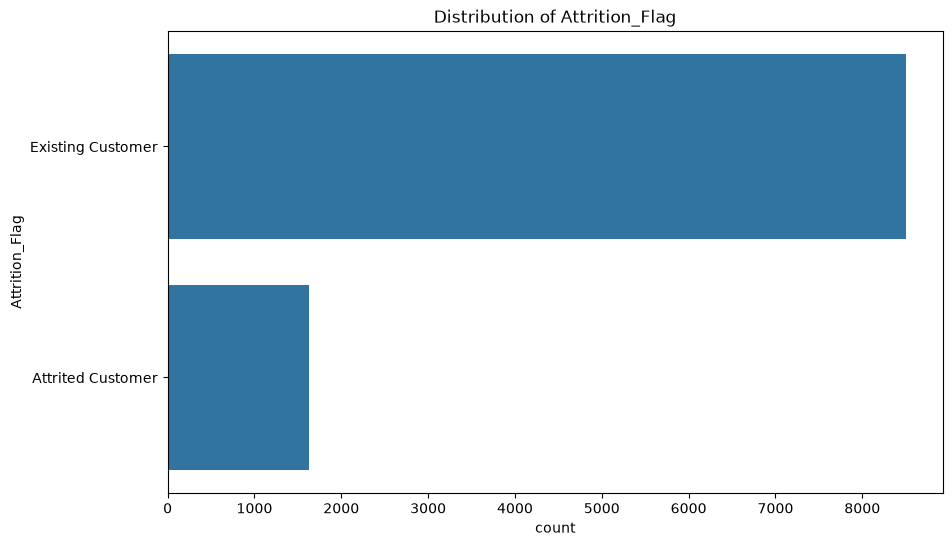

In [3]:

df.head()
# Exploration de la variable cible
df['Attrition_Flag'].value_counts()
plt.figure(figsize=(10, 6))
sns.countplot(df['Attrition_Flag'])
plt.title('Distribution of Attrition_Flag')
plt.show()


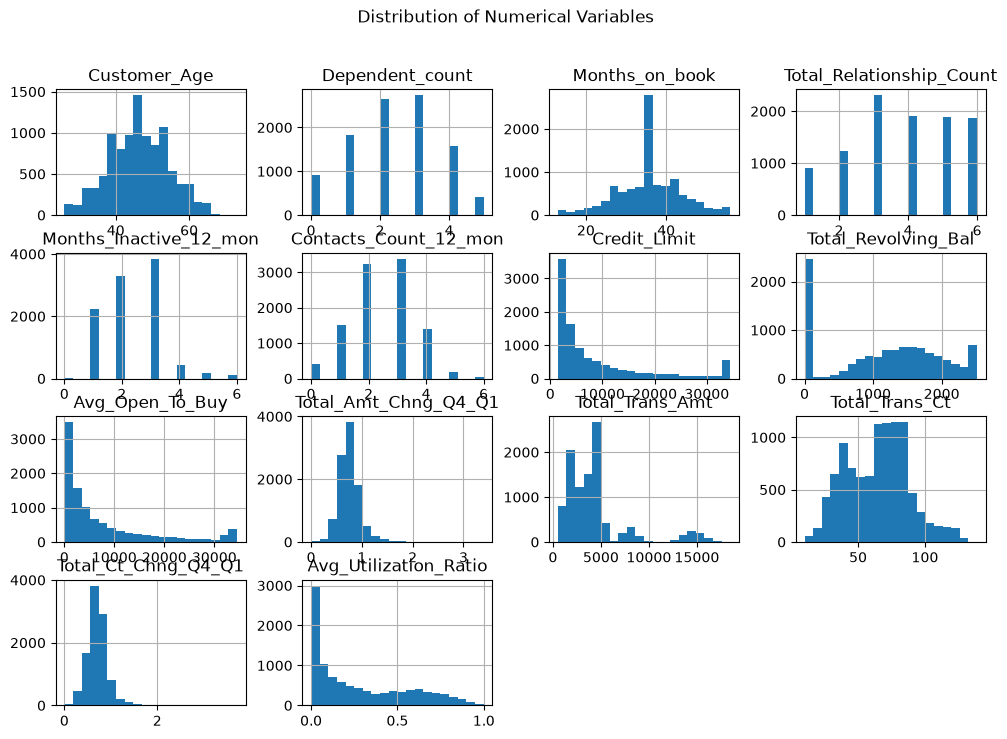

In [4]:
#Distribution des variables numériques
df.describe()
df.hist(figsize=(12, 8),bins=20)
plt.suptitle("Distribution of Numerical Variables")
plt.show()

In [5]:
# Identifier les variables catégorielles
# (select_dtypes(include=["object"]) ne fonctionne plus de façon fiable avec les
# versions récentes de pandas, qui utilisent un dtype "str" dédié : on exclut donc
# plutôt les colonnes numériques.)
cat_features = df.select_dtypes(exclude=[np.number]).columns

# Afficher les catégories et leurs valeurs uniques
for col in cat_features:
    if col == "Attrition_Flag":
        continue
    print(f"\n📌 {col} : {df[col].nunique()} catégories")
    print(df[col].unique())  # Afficher les valeurs uniques


📌 Gender : 2 catégories
<StringArray>
['M', 'F']
Length: 2, dtype: str

📌 Education_Level : 7 catégories
<StringArray>
[  'High School',      'Graduate',    'Uneducated',       'Unknown',
       'College', 'Post-Graduate',     'Doctorate']
Length: 7, dtype: str

📌 Marital_Status : 4 catégories
<StringArray>
['Married', 'Single', 'Unknown', 'Divorced']
Length: 4, dtype: str

📌 Income_Category : 6 catégories
<StringArray>
[   '$60K - $80K', 'Less than $40K',   '$80K - $120K',    '$40K - $60K',
        '$120K +',        'Unknown']
Length: 6, dtype: str

📌 Card_Category : 4 catégories
<StringArray>
['Blue', 'Gold', 'Silver', 'Platinum']
Length: 4, dtype: str


**Réponse.** Le jeu de données est fortement déséquilibré : environ 84 % de clients
existants contre 16 % de clients partis (`Attrited Customer`). Cela va biaiser le
modèle vers la classe majoritaire : une forêt aléatoire entraînée sans pondération aura
tendance à privilégier la prédiction *Existing Customer*, ce qui se vérifie en Partie 3
par un rappel élevé sur cette classe (0,99) mais nettement plus faible sur la classe
minoritaire (0,59). Les explications LIME/SHAP hériteront de ce biais : comme le modèle
discrimine moins bien les cas de la classe minoritaire, les explications locales autour
de ces instances sont probablement moins fiables que pour des instances de la classe
majoritaire, sur laquelle le modèle est plus confiant.

---
## Partie 2 - Préparation des données

### Séparez les attributs (`X`) de la cible (`y`)

In [6]:
# Séparer les données
X = df.drop(columns=["Attrition_Flag"])
y = df["Attrition_Flag"]

print(X.shape, y.shape)

(10127, 19) (10127,)


### A. Attributs numériques

* Est-il nécessaire de normaliser les attributs numériques ? Pourquoi ?

### B. Transformer les attributs catégoriels en valeurs numériques

* Est-il nécessaire de créer des *one-hots* ? Pourquoi ?

#### Encodage *(attention, il y a un twist)*

* Vous pouvez utiliser un ``LabelEncoder`` de Scikit-Learn
* ou encore générer des codes à partir du dataframe, e.g. ``X['attribut'].astype('category').cat.codes`` où `attribut` est le nom d'un attribut des données)

**Réponses.**

**A. Normalisation.** Non, ce n'est pas nécessaire ici : la forêt aléatoire est un
modèle à base d'arbres de décision, qui choisit des seuils de coupure sur chaque
variable indépendamment des autres. Les arbres sont invariants à toute transformation
monotone (donc à la normalisation) : une mise à l'échelle ne changerait ni la structure
des arbres ni les prédictions. La normalisation serait nécessaire pour un modèle
sensible aux distances ou aux magnitudes (k-NN, SVM, régression linéaire/logistique
régularisée, réseaux de neurones).

**B. One-hot encoding.** Non : un one-hot encoding créerait une colonne binaire par
catégorie, ce qui (1) augmenterait inutilement la dimensionnalité pour une forêt
aléatoire, qui peut déjà découper directement sur des valeurs discrètes, et (2)
compliquerait l'usage de LIME, qui attend un jeu d'attributs correspondant un à un aux
colonnes originales du jeu de données pour perturber et présenter les explications de
façon interprétable (perturber une seule colonne one-hot n'a pas de sens sémantique
isolément). On utilise donc un simple encodage ordinal (codes de catégorie), associé
aux méta-données `categorical_features` / `categorical_names` qui permettent à LIME de
traiter ces colonnes comme catégorielles (permutation par catégorie plutôt que
perturbation continue) et d'afficher les valeurs d'origine plutôt que les codes
numériques dans les explications.

#### Twist: méta-données pour LIME
LIME aura besoin:

1. D'une liste contenant le nom des attributs (``X.columns``)
2. D'une liste des indices des colonnes des attributs catégoriels
3. D'un dictionnaire comportant le mapping des valeurs des catégories avec leurs encodages numériques

Par exemple, pour le présent dataset:
* Indices des colonnes des attributs: ``categorical_features`` $\rightarrow$ ``[1,3,4,5,6]``
* Mapping codes/valeurs des attributs: ``categorical_names`` $\rightarrow$ ``{1: {0: 'F', 1: 'M'}, 3: {0: 'College', 1: 'Doctorate', 2: 'Graduate', 3: 'High School', 4: 'Post-Graduate', 5: 'Uneducated', 6: 'Unknown'}, 4: {0: 'Divorced', 1: 'Married', 2: 'Single', 3: 'Unknown'}, 5: {0: '$120K +', 1: '$40K - $60K', 2: '$60K - $80K', 3: '$80K - $120K', 4: 'Less than $40K', 5: 'Unknown'}, 6: {0: 'Blue', 1: 'Gold', 2: 'Platinum', 3: 'Silver'}}``

**$\Rightarrow$ Créez ces méta-données en même temps que vous encodez les attributs catégoriels**

In [7]:
# Encoder les attributs catégoriels et préparer les méta-données pour LIME
categorical_features = []
categorical_names = {}
X_encoded = X.copy()

for idx, col in enumerate(X.columns):
    if col in cat_features:
        codes = X[col].astype("category").cat.codes
        categories = X[col].astype("category").cat.categories
        X_encoded[col] = codes
        categorical_features.append(idx)
        categorical_names[idx] = dict(enumerate(categories))

print("categorical_features:", categorical_features)
print("categorical_names:", categorical_names)

categorical_features: [1, 3, 4, 5, 6]
categorical_names: {1: {0: 'F', 1: 'M'}, 3: {0: 'College', 1: 'Doctorate', 2: 'Graduate', 3: 'High School', 4: 'Post-Graduate', 5: 'Uneducated', 6: 'Unknown'}, 4: {0: 'Divorced', 1: 'Married', 2: 'Single', 3: 'Unknown'}, 5: {0: '$120K +', 1: '$40K - $60K', 2: '$60K - $80K', 3: '$80K - $120K', 4: 'Less than $40K', 5: 'Unknown'}, 6: {0: 'Blue', 1: 'Gold', 2: 'Platinum', 3: 'Silver'}}


### C. Split des données
* Séparez vos données en un jeu d'entrainement et un jeu de test *(fixez la graine !)*

In [8]:
# Split des données en train / test (graine fixée pour la reproductibilité)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (8101, 19), Test: (2026, 19)


---
## Partie 3 - Entraîner une forêt aléatoire sur les données

* Instanciez une forêt aléatoire avec 10 estimateurs, d'une profondeur maximale de 6 *(fixez la graine !)*
* Entraînez le modèle sur vos données d'entraînement
* Calculez l'exactitude de votre modèle
* \[optionnel\] Évaluez plus rigoureusement votre modèle (matrice de confusions, rappel, précision, F1-score, ...)

In [9]:
from sklearn.metrics import classification_report, confusion_matrix

# Instancier, entraîner et évaluer une forêt aléatoire
clf = RandomForestClassifier(n_estimators=10, max_depth=6, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")

# Évaluation plus détaillée (optionnel)
print(classification_report(y_test, y_pred))
print("Matrice de confusion (lignes = vrai, colonnes = prédit) :")
print(f"Classes : {list(clf.classes_)}")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9235

                   precision    recall  f1-score   support

Attrited Customer       0.89      0.59      0.71       325
Existing Customer       0.93      0.99      0.96      1701

         accuracy                           0.92      2026
        macro avg       0.91      0.79      0.83      2026
     weighted avg       0.92      0.92      0.92      2026

Matrice de confusion (lignes = vrai, colonnes = prédit) :
Classes : ['Attrited Customer', 'Existing Customer']
[[ 193  132]
 [  23 1678]]


---
## Partie 4 - génération d'explications

### A. LIME

[Documentation de LIME pour les données tabulaires](https://lime-ml.readthedocs.io/en/latest/lime.html#module-lime.lime_tabular)

#### Instanciez un *explainer* :``LimeTabularExplainer()``
Vous avez besoin de spécifier dans le constructeur:
* Les données ayant permis d'entraîner le modèle *(en format numpy)*
* Les noms des attributs
* Les valeurs que peut prendre la cible
* La liste des indices des variables catégorielles
* Le mapping entre les codes des variables catégorielles et leurs valeurs

In [10]:
# Instancier un explainer LIME
explainer_lime = LimeTabularExplainer(
    X_train.values,
    feature_names=X.columns.tolist(),
    class_names=clf.classes_,
    categorical_features=categorical_features,
    categorical_names=categorical_names,
)

#### Utilisez l'*explainer* pour générer l'explication d'une instance: ``explain_instance()``

(la première instance du jeu de test, par exemple) 

``explain_instance()`` renvoie un objet ``Explanation`` qui peut être affiché:
* dans un notebook avec ``explanation.show_in_notebook(show_table=True)``
* sous forme de figure pyplot avec ``explanation.as_pyplot_figure()``
* sous forme d'une liste avec ``as_list()``

1. Testez l'*explainer* avec différents nombres d'attributs à utiliser pour l'explication (``num_features``), ainsi que différents nombre de perturbations de l'instance (``num_samples``)
   * Les explications diffèrent-elles?
2. Pour différentes configurations, générez plusieurs fois l'explication: l'explication est-elle toujours la même?

**/!\\** Ne fixez pas la graine du RNG de numpy, sans quoi les explications seront les mêmes pour différentes générations à partir d'une configuration donnée

Vraie classe de l'instance : Existing Customer
Probabilités prédites : {'Attrited Customer': np.float64(0.04571264900154622), 'Existing Customer': np.float64(0.9542873509984539)}

=== num_features=6, num_samples=500 ===


  Total_Trans_Ct > 80.00                        +0.1233


  Total_Relationship_Count <= 3.00              -0.0736
  Total_Trans_Amt > 4730.00                     -0.0700
  Total_Revolving_Bal > 1781.00                 +0.0590
  0.70 < Total_Ct_Chng_Q4_Q1 <= 0.82            +0.0417
  Marital_Status=Single                         +0.0201

=== num_features=10, num_samples=5000 ===


  Total_Trans_Ct > 80.00                        +0.1177
  Total_Relationship_Count <= 3.00              -0.0812
  Total_Trans_Amt > 4730.00                     -0.0501
  Total_Revolving_Bal > 1781.00                 +0.0371
  0.70 < Total_Ct_Chng_Q4_Q1 <= 0.82            +0.0358
  Gender=M                                      +0.0202
  Contacts_Count_12_mon <= 2.00                 +0.0096
  Card_Category=Silver                          -0.0095
  Marital_Status=Single                         +0.0083
  Education_Level=Graduate                      +0.0077

=== Stabilité : 3 exécutions successives (num_features=6, num_samples=500) ===


--- run 1 ---
  Total_Trans_Ct > 80.00                        +0.1137
  Total_Relationship_Count <= 3.00              -0.0724
  Total_Trans_Amt > 4730.00                     -0.0616
  Total_Revolving_Bal > 1781.00                 +0.0353
  Contacts_Count_12_mon <= 2.00                 +0.0332
  46.00 < Customer_Age <= 52.00                 -0.0328


--- run 2 ---
  Total_Trans_Ct > 80.00                        +0.1272
  Total_Relationship_Count <= 3.00              -0.0837
  Total_Trans_Amt > 4730.00                     -0.0677
  Total_Revolving_Bal > 1781.00                 +0.0466
  Income_Category=$60K - $80K                   -0.0442
  0.70 < Total_Ct_Chng_Q4_Q1 <= 0.82            +0.0369


--- run 3 ---
  Total_Trans_Ct > 80.00                        +0.1356
  Total_Relationship_Count <= 3.00              -0.0929
  Card_Category=Silver                          +0.0475
  Total_Trans_Amt > 4730.00                     -0.0410
  Total_Revolving_Bal > 1781.00                 +0.0378
  Marital_Status=Single                         +0.0304


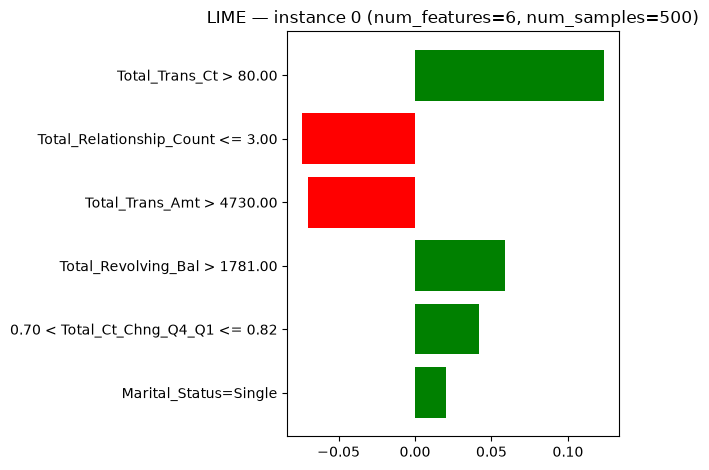

In [11]:
import warnings
# LimeTabularExplainer appelle predict_proba() sur des tableaux numpy sans noms de
# colonnes, ce qui déclenche un UserWarning sklearn sans conséquence sur le résultat.
warnings.filterwarnings("ignore", category=UserWarning)

# Génération d'explications pour la première instance du jeu de test,
# avec différentes configurations (num_features, num_samples)
instance = X_test.values[0]
print(f"Vraie classe de l'instance : {y_test.iloc[0]}")
print(f"Probabilités prédites : {dict(zip(clf.classes_, clf.predict_proba(X_test.iloc[[0]])[0]))}\n")

print("=== num_features=6, num_samples=500 ===")
exp1 = explainer_lime.explain_instance(instance, clf.predict_proba, num_features=6, num_samples=500)
for feat, weight in exp1.as_list():
    print(f"  {feat:45s} {weight:+.4f}")

print("\n=== num_features=10, num_samples=5000 ===")
exp2 = explainer_lime.explain_instance(instance, clf.predict_proba, num_features=10, num_samples=5000)
for feat, weight in exp2.as_list():
    print(f"  {feat:45s} {weight:+.4f}")

# Vérification de la stabilité : 3 générations successives de la même configuration
# (num_features=6, num_samples=500), sans fixer la graine du générateur aléatoire
print("\n=== Stabilité : 3 exécutions successives (num_features=6, num_samples=500) ===")
for run in range(3):
    exp = explainer_lime.explain_instance(instance, clf.predict_proba, num_features=6, num_samples=500)
    print(f"--- run {run + 1} ---")
    for feat, weight in exp.as_list():
        print(f"  {feat:45s} {weight:+.4f}")

exp1.as_pyplot_figure()
plt.title("LIME — instance 0 (num_features=6, num_samples=500)")
plt.tight_layout()
plt.show()

**Réponses.**

Les explications diffèrent selon la configuration et d'une génération à l'autre pour
une même configuration. L'attribut le plus important (`Total_Trans_Ct > 80.00`) reste
stable en signe et en rang sur les 3 exécutions ci-dessus (run 1 à 3), mais son poids
varie (de +0,114 à +0,136 selon l'exécution), et certains attributs de rang inférieur apparaissent ou
disparaissent d'une exécution à l'autre (ex. `Total_Ct_Chng_Q4_Q1`, `Gender=M`).
Augmenter `num_samples` (500 → 5000) fait apparaître davantage d'attributs pertinents
dans le top-10 et tend à stabiliser un peu les poids, mais ne supprime pas la
variabilité intrinsèque liée à l'échantillonnage aléatoire des perturbations utilisées
pour ajuster le modèle local.

---
#### B. SHAP

1. Instancier un ``TreeExplainer`` sur le modèle
2. Calculer les valeurs de Shapley sur les instances du jeu de test (i.e. calculer les explications pour chaque instance du jeu de test)
3. Afficher l'explication de la première instance du jeu de test
   * Avec un histogramme: `shap.plots.bar()`
   * Avec un diagramme en cascade: `shap.plots.waterfall()`
   * Dans les deux cas, le paramètre `max_displays` permet de choisir combien d'attributs on souhaite afficher dans l'explication
4. Quelles sont les informations présentes sur l'histogramme et sur le diagramme en cascade ?
5. L'explication est-elle la même que celle(s) générée(s) par LIME ?

*Note sur les valeurs de Shapley calculée:*

Les valeurs de Shapley sont stockées dans un tableau de dimension `(n_samples, n_variables, n_classes)`. `n_classes` correspond au nombres de classes apprises par le modèle `clf.classes_`, ici `['Attrited Customer' 'Existing Customer']`.

Pour l'affichage d'une explication, il faut donc sélectionner l'instance *et* spécifier la classe à expliquer (ici 0 pour *attrited* ou 1 pour *existing*).


In [12]:
shap.initjs() # pour permettre la visualisation JS dans le notebook

In [13]:
# Instancier un TreeExplainer et calculer les valeurs de Shapley sur le jeu de test
explainer_shap = shap.TreeExplainer(clf)
shap_values = explainer_shap(X_test)

print("Forme des valeurs de Shapley :", shap_values.shape)  # (n_samples, n_features, n_classes)
print("Classes du modèle :", list(clf.classes_))

Forme des valeurs de Shapley : (2026, 19, 2)
Classes du modèle : ['Attrited Customer', 'Existing Customer']


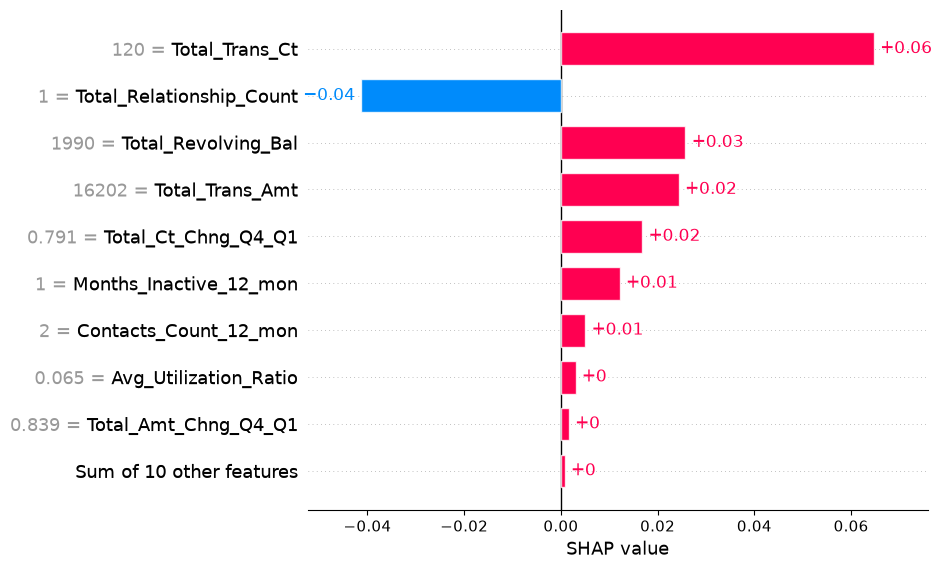

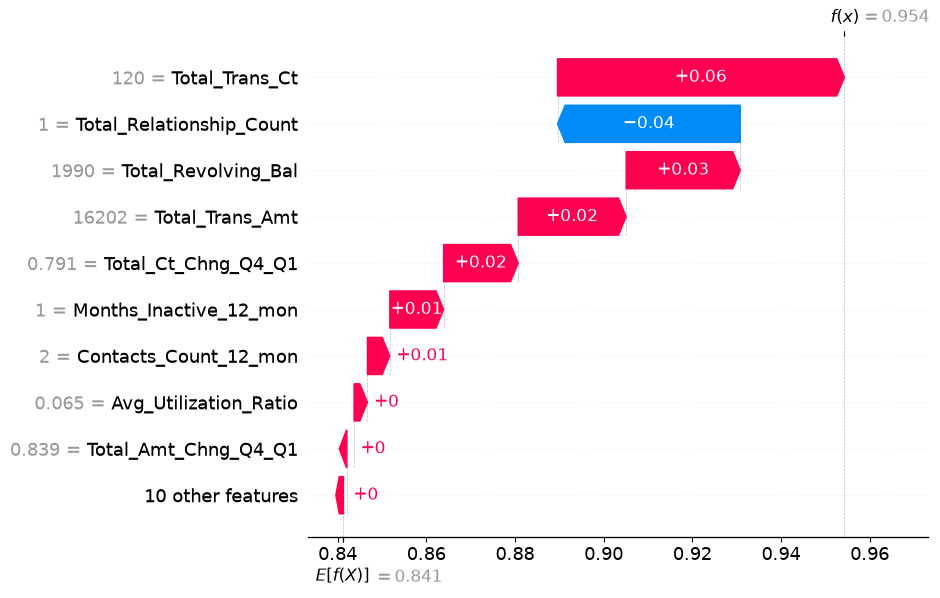

In [14]:
# Explication de la première instance du jeu de test, pour la classe "Existing Customer" (indice 1)
shap.plots.bar(shap_values[0, :, 1])
shap.plots.waterfall(shap_values[0, :, 1])

**Réponses.**

L'histogramme (`shap.plots.bar`) affiche, pour l'instance choisie, la contribution
(valeur de Shapley) de chaque attribut à la prédiction, triée par magnitude
décroissante. Le diagramme en cascade (`shap.plots.waterfall`) montre la même
information de façon cumulative : il part de la valeur de base $E[f(X)] \approx 0{,}841$
(la prédiction moyenne du modèle sur le jeu de données, pour la classe *Existing
Customer*) et ajoute successivement la contribution de chaque attribut jusqu'à
atteindre la prédiction finale $f(x) \approx 0{,}954$ pour ce client précis — ce qui
rend explicite comment on passe de la prédiction moyenne à la prédiction individuelle.

Les attributs identifiés sont globalement les mêmes que ceux de LIME pour cette
instance (`Total_Trans_Ct`, `Total_Relationship_Count`, `Total_Revolving_Bal`,
`Total_Trans_Amt` dominent dans les deux cas), mais contrairement à LIME, SHAP donne des
poids identiques à chaque exécution (déterministe pour un `TreeExplainer`, calculé
exactement à partir de la structure des arbres plutôt qu'estimé par échantillonnage).

#### SHAP: explication globale

1. Expliquer (no pun) le résultat de la cellule ci-dessous
2. Les attributs contribuants le plus aux prédictions sur le jeu de test sont-elles les mêmes que pour la première instance seulement ? Leur classement est-il le même ?
3. Est-ce possible d'obtenir ce type d'information "nativement" avec LIME ?
   * Est-ce que cela est / serait pertinent ? Pourquoi ?

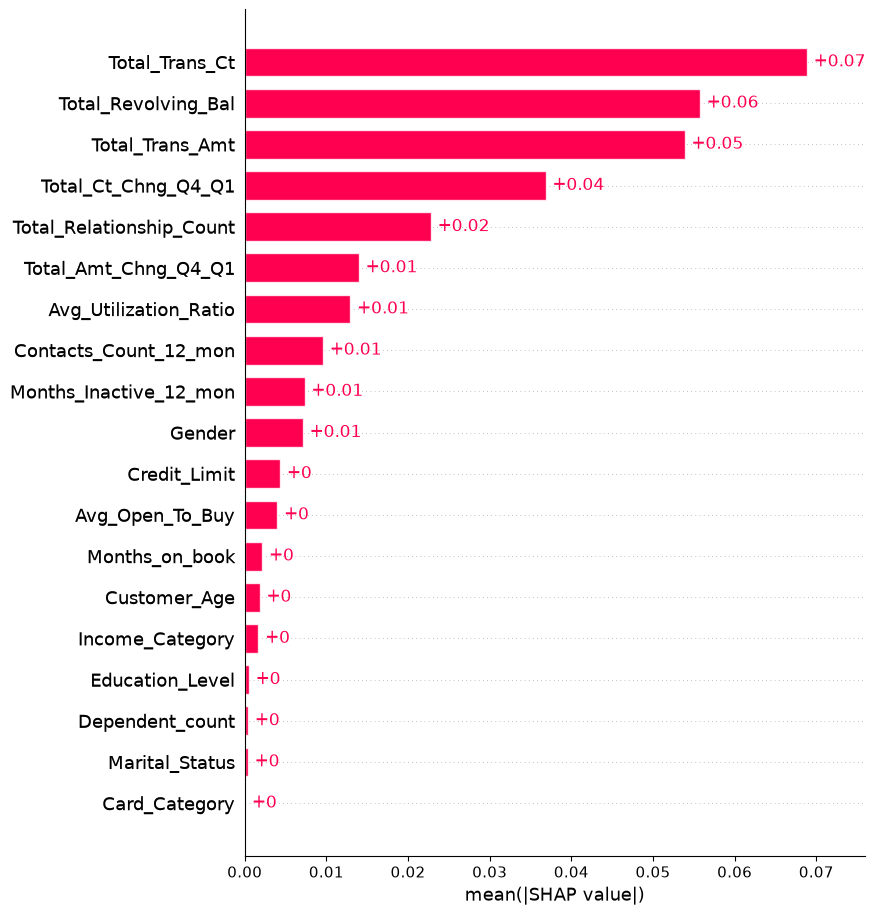

In [15]:
shap.plots.bar(shap_values[:, :, 1], max_display=20)

### Réponses — SHAP, explication globale

1. Le graphique ci-dessus agrège la contribution absolue moyenne de chaque attribut
   (`mean(|valeur de Shapley|)`) sur l'ensemble des instances du jeu de test, pour la
   classe *Existing Customer* : plus la barre est longue, plus l'attribut influence en
   moyenne les prédictions du modèle sur tout le jeu de test, indépendamment du signe
   de son effet.

2. Les attributs dominants au niveau global (`Total_Trans_Ct`, `Total_Revolving_Bal`,
   `Total_Trans_Amt`, `Total_Ct_Chng_Q4_Q1`, `Total_Relationship_Count`) recoupent
   largement ceux identifiés pour la première instance seule, mais l'ordre exact
   diffère : `Total_Revolving_Bal` et `Total_Trans_Amt` passent devant
   `Total_Ct_Chng_Q4_Q1` au niveau global, alors que pour l'instance 0 c'est
   `Total_Relationship_Count` qui arrive en 2ᵉ position. Les variables démographiques
   (genre, âge, éducation, statut marital, revenu, type de carte) contribuent très peu,
   aussi bien localement que globalement : le modèle s'appuie presque exclusivement sur
   le comportement transactionnel du client.

3. LIME ne fournit pas nativement d'explication globale agrégée sur le jeu de test : il
   génère des explications locales, instance par instance. Pour obtenir une vue globale
   équivalente, il faudrait moyenner explicitement les poids obtenus sur un grand
   nombre d'instances — une démarche non intégrée à l'outil et coûteuse en temps de
   calcul, puisqu'un modèle local différent doit être ré-ajusté pour chaque instance.
   SHAP, lui, calcule nativement des valeurs cohérentes et agrégeables entre elles
   (propriété d'additivité des valeurs de Shapley), ce qui rend cette agrégation
   immédiate et pertinente pour identifier les attributs qui comptent le plus à
   l'échelle du portefeuille de clients, au-delà d'un cas individuel.

---
## Partie 5 - Réflexions et conclusions

1. Modèle vs. réalité
   * Dans quelle mesure les explications du modèle permettent-elles d'élucider les causes de la perte de clients?
   * Si les données étaient plus équilibrées, les explications seraient elles plus éclairantes sur la cause du phénomène?
2. Explications locales et globales
   * En quoi LIME illustre la notion de *sous-détermination* abordée en cours?
   * En quoi une explication locale peut-elle conduire à une extrapolation abusive?
   * Expliquer globalement un modèle permet-il de prendre en considération des cas singuliers?
   * Donnez un exemple de scénario dans lequel une explication locale (resp. globale) est pertinente.
3. Limites techniques / méthodologiques
   * Pourquoi les explications générées par LIME sont-elles instables?
   * Comment l'ancrage théorique de SHAP permet-il de pallier l'instabilité de LIME?
4. Une touche d'éthique
   * En quoi le problème de sous-détermination peut-il engendrer des problèmes d'inéquité?
   * La génération d'explications permet-elle d'apporter de l'objectivité aux acteurs? (quels acteurs?)

### Réponses — Partie 5

**1. Modèle vs. réalité**

Les explications du modèle (dominées par `Total_Trans_Ct`, `Total_Trans_Amt`,
`Total_Revolving_Bal`, `Total_Ct_Chng_Q4_Q1`) doivent être interprétées avec prudence
comme des « causes » de l'attrition. Ces variables mesurent l'activité transactionnelle
*récente* du client, qui baisse mécaniquement lorsqu'un client est en train de partir ou
vient de partir : il s'agit en bonne partie d'un effet de la définition même du churn
(un client « Attrited » cesse par construction d'utiliser sa carte) plutôt que d'une
cause profonde et actionnable (pourquoi le client a-t-il décidé de partir ?). Le modèle
capture des symptômes corrélés à l'attrition plus que des causes racines.

Un jeu de données plus équilibré (plus d'exemples de clients partis) améliorerait
probablement le rappel du modèle sur la classe minoritaire, mais ne changerait pas ce
biais structurel : les variables disponibles resteraient les mêmes indicateurs
transactionnels, sans variable de satisfaction client, de service, ou de contexte de vie
qui pourrait révéler une cause réelle du départ.

**2. Explications locales et globales**

LIME illustre la notion de sous-détermination : pour une même instance et un même
modèle, plusieurs modèles linéaires locaux différents (donc plusieurs explications
différentes) sont compatibles avec les données observées localement — le résultat
dépend de l'échantillon aléatoire de perturbations utilisé, comme observé sur les 3
exécutions successives à configuration identique (Partie 4A) : le poids de
`Total_Trans_Ct` varie par exemple entre +0.089 et +0.115. Rien dans les données ne
détermine une unique « bonne » explication.

Une explication locale peut conduire à une extrapolation abusive si l'on généralise la
contribution observée pour une instance particulière (ex. « `Total_Relationship_Count`
faible augmente le risque de churn ») à l'ensemble de la population, sans vérifier que
cette relation est stable ailleurs dans l'espace des attributs.

Expliquer un modèle globalement (moyenne sur tout le jeu de test) masque par
construction les cas singuliers : un attribut peu important en moyenne peut être
déterminant pour un sous-groupe ou une instance précise — c'est exactement ce qu'on
observe en comparant le classement global des attributs (Partie 4B) à celui de
l'instance 0 seule, où `Total_Relationship_Count` remonte en 2ᵉ position.

Exemple : une explication **locale** est pertinente pour un conseiller bancaire qui doit
justifier à un client précis pourquoi le modèle prédit qu'il va partir, et discuter avec
lui d'actions individuelles. Une explication **globale** est pertinente pour l'équipe
produit qui veut prioriser, à l'échelle du système d'information, les leviers généraux
à développer pour réduire le churn dans son ensemble.

**3. Limites techniques / méthodologiques**

Les explications de LIME sont instables car elles reposent sur un échantillonnage
aléatoire de perturbations autour de l'instance à expliquer, puis sur l'ajustement d'un
modèle linéaire *approximatif* sur cet échantillon : deux tirages aléatoires différents
produisent deux voisinages différents, donc potentiellement deux explications
différentes — en particulier avec un faible `num_samples`.

Les valeurs de Shapley reposent sur un ancrage théorique en théorie des jeux
coopératifs (répartition équitable de la contribution de chaque attribut à l'écart
entre la prédiction et la valeur de base, sur toutes les coalitions d'attributs
possibles) : pour un modèle et une instance donnés, elles sont définies de façon unique.
Un `TreeExplainer` les calcule même exactement à partir de la structure des arbres,
sans échantillonnage aléatoire — d'où la stabilité observée par rapport à LIME.

**4. Une touche d'éthique**

La sous-détermination peut engendrer de l'inéquité si deux exécutions de LIME, sur le
même client, produisent des explications différentes sur la base desquelles on
justifierait des décisions différentes (ex. accorder ou refuser une offre de
fidélisation) : la décision devient difficile à auditer et à contester de façon
cohérente, puisqu'une autre exécution aurait pu produire une autre justification.

La génération d'explications n'apporte pas d'objectivité en soi : elle rend visible le
raisonnement du modèle, mais si le modèle reproduit des biais, l'explication rend ce
biais plus lisible sans le corriger. Elle peut apporter de l'objectivité aux acteurs qui
*auditent* le modèle (data scientists, régulateurs) en leur donnant un moyen de vérifier
a posteriori si le modèle se fonde sur des critères légitimes ; elle reste en revanche
insuffisante pour garantir l'objectivité vis-à-vis du client final, qui n'a pas les
moyens de vérifier lui-même la validité de l'explication reçue.